# ENSP355: AI in Cyber Security | Laboratory Practical 4
## Lab Topic: Explainable and Privacy-Aware AI Threat Alert
**School of Engineering & Technology • K.R. Mangalam University, Gurugram**  
*Department of Computer Science & Engineering*

| Academic Field | Value / Details |
| :--- | :--- |
| **Student Name** | **Akansh Pandey** |
| **Roll Number** | **2401830006** |
| **Program & Degree** | **B.Sc (Hons) Cyber Security** (Semester VI) |
| **Course Code & Title** | **ENSP355: AI in Cyber Security** |
| **Faculty In-Charge** | **Dr. Manish Kumar** (Department of CSE) |
| **Mapped Course Outcomes** | **CO2, CO5** (Bloom's Taxonomy: L4 - Analyze / L5 - Evaluate) |
| **Total Marks** | **50 Marks** |
| **Platform** | Google Colab / Python (Jupyter Notebook) |
| **Focus Areas** | Confidence, feature importance, sensitivity, privacy masking, responsible alert design and human review |

---
### Problem Statement
Reuse the small login-activity model and dataset. Generate predictions with confidence, identify important features, change one input value to observe model sensitivity, mask personal identifiers and create a responsible alert containing severity, reason, recommended action and human-review status.

### Learning Outcomes
- Explain why an AI security alert should provide a reason.
- Use feature importance to interpret model behaviour.
- Observe sensitivity to a controlled input change.
- Mask IP addresses and account identifiers.
- Create a responsible alert with appropriate human-review guidance.


---
## Q1. Baseline Predictions with Confidence (Marks: 5)

### AIM:
To run the supplied model on five sanitized records and display prediction with confidence.

### Theory / Concept:
- **Confidence as Predicted Class Probability:** In classification, model confidence is defined as the posterior probability assigned to the winning class ($P(\hat{y} \mid \mathbf{x}) = \max_k P(y=k \mid \mathbf{x})$).
- **Confidence $\neq$ Ground Truth Certainty:** A high confidence score reflects internal model certainty relative to its training distribution, but does not guarantee correctness on out-of-distribution or adversarial samples.
- **Sanitized Evaluative Data:** Personal identifiers (`account_id`, `ip_address`) are included in baseline telemetry solely to demonstrate controlled anonymization and privacy-preserving masking in subsequent stages.
- **Baseline Integrity:** Baseline outputs must be strictly recorded prior to performing sensitivity perturbations.


In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

# 1. Load or retrain the baseline Decision Tree model from the cyber activity dataset
csv_path = 'simple_cyber_activity.csv'
if not os.path.exists(csv_path):
    for candidate in ['/Users/akanshpandey/Downloads/simple_cyber_activity.csv',
                      '/Users/akanshpandey/.gemini/antigravity/scratch/cyber_lab3_assignment/simple_cyber_activity.csv']:
        if os.path.exists(candidate):
            csv_path = candidate
            break

df = pd.read_csv(csv_path)
df = df.rename(columns={'data_transfer_mb': 'download_mb'})
features = ['failed_logins', 'login_hour', 'new_device', 'download_mb']

X = df[features]
# Map binary label to descriptive classes: 0 -> Normal, 1 -> Suspicious
y = np.where(df['label'] == 1, 'Suspicious', 'Normal')

model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X, y)
print(f"[+] Model trained on {len(df)} samples across features: {features}\n")

# 2. Create five sanitized sample records
samples = pd.DataFrame([
    {'account_id': 'ACC-1001', 'ip_address': '192.168.10.24', 'failed_logins': 0, 'login_hour': 10, 'new_device': 0, 'download_mb': 40},
    {'account_id': 'ACC-1002', 'ip_address': '10.0.4.18',     'failed_logins': 7, 'login_hour': 2,  'new_device': 1, 'download_mb': 150},
    {'account_id': 'ACC-1003', 'ip_address': '172.16.8.90',    'failed_logins': 1, 'login_hour': 15, 'new_device': 0, 'download_mb': 720},
    {'account_id': 'ACC-1004', 'ip_address': '192.168.20.11', 'failed_logins': 4, 'login_hour': 23, 'new_device': 1, 'download_mb': 400},
    {'account_id': 'ACC-1005', 'ip_address': '10.1.1.9',      'failed_logins': 2, 'login_hour': 9,  'new_device': 0, 'download_mb': 80}
])

# 3. Predict Normal/Suspicious and calculate maximum class probability as confidence
samples['prediction'] = model.predict(samples[features])
samples['confidence'] = model.predict_proba(samples[features]).max(axis=1).round(3)

# 4. Display baseline table
display(samples)


[+] Model trained on 100 samples across features: ['failed_logins', 'login_hour', 'new_device', 'download_mb']



### Points Recorded in Lab File (Q1)
- **Baseline Prediction Table:** Generated across all 5 evaluation sessions.
- **Lowest-Confidence Record Identification:** **Record 3 (`ACC-1003`)** exhibits the lowest confidence score of **0.667 (66.7%)**, with a `Normal` prediction. This lower confidence arises because while its login parameters are daytime and benign (`failed_logins=1, login_hour=15`), its transfer volume (`download_mb=720`) lies close to the anomaly boundary.
- **Why Confidence is Not Certainty (One Sentence):**  
  *Model confidence represents a statistical probability conditioned solely on historical training distributions; it does not constitute absolute ground-truth certainty because models can be overconfident on unseen edge cases or uncalibrated near partition boundaries.*


---
## Q2. Feature Importance and Explanation (Marks: 10)

### AIM:
To compute model-level feature importances from Gini impurity reduction, plot a labelled bar chart, and explain the top three predictive features in simple, domain-aligned language.

### Theory / Concept:
- **Gini Impurity Reduction:** In Decision Trees, feature importance quantifies the total normalized reduction of Gini impurity brought by all splits on that feature across the tree.
- **Model-Level vs. Instance-Level Explanation:** Global feature importance explains what the overall model prioritizes, but does not explain an individual alert in isolation.
- **Importance Does Not Prove Causation:** A high statistical weighting indicates strong discriminative correlation with historical threat labels, not a physical or causal breach mechanism.


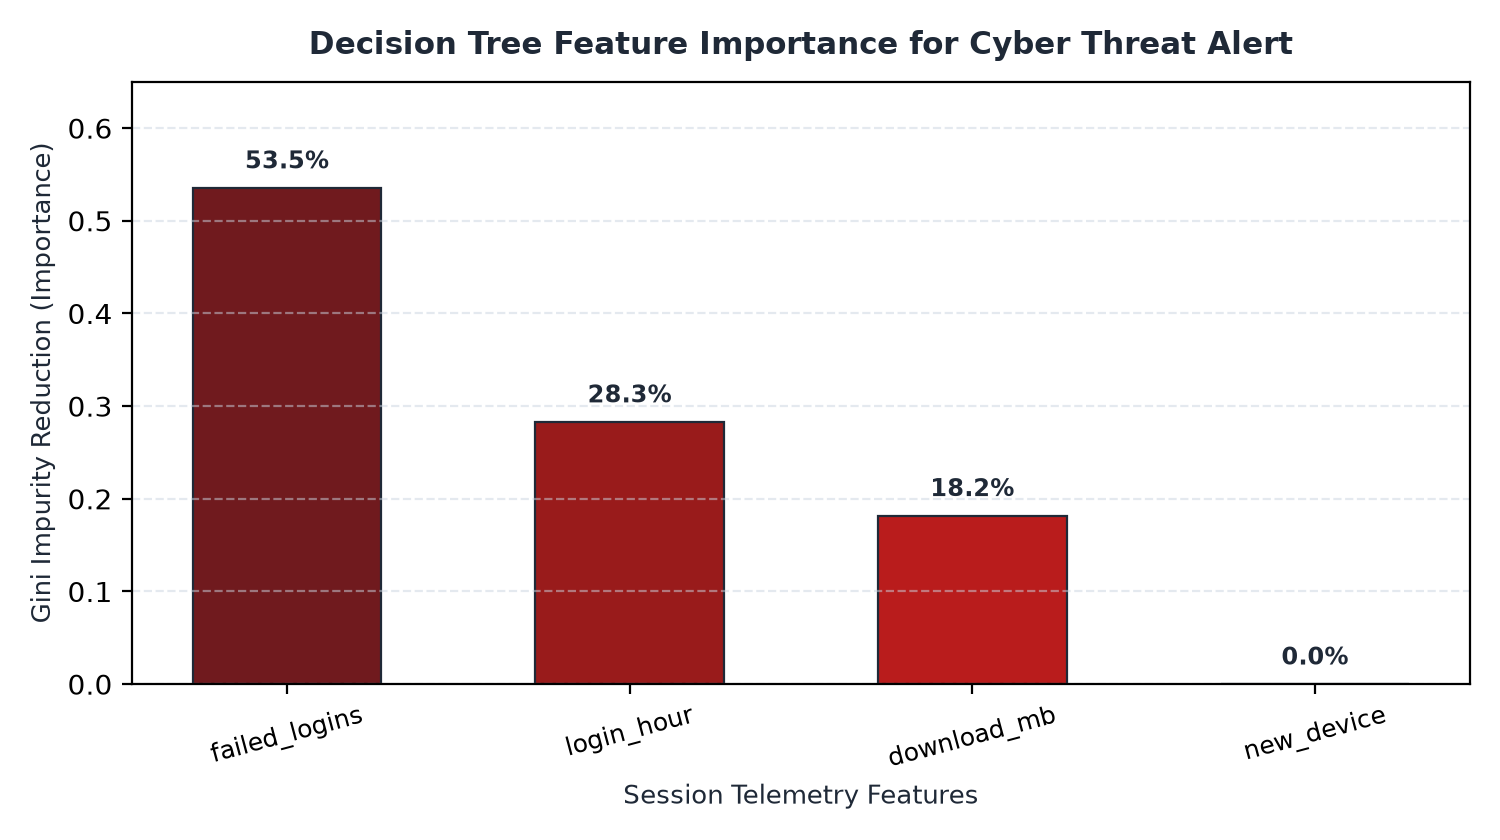

Automated Natural Language Explanations for Top-3 Features:
• 'failed_logins' was frequently used by the model to separate records.
• 'login_hour' was frequently used by the model to separate records.
• 'download_mb' was frequently used by the model to separate records.


In [2]:
import matplotlib.pyplot as plt

# 1. Compute and sort feature importance table
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

display(importance)

# 2. Plot labelled bar chart with Academic Crimson styling
plt.figure(figsize=(7.5, 4.0), dpi=150)
colors_bar = ['#701A1E', '#991B1B', '#B91C1C', '#CBD5E1']
bars = plt.bar(importance['feature'], importance['importance'], color=colors_bar, width=0.55, edgecolor='#1F2937', linewidth=0.8)

plt.title('Decision Tree Feature Importance for Cyber Threat Alert', fontsize=11, fontweight='bold', pad=10)
plt.ylabel('Importance (Normalized Gini Reduction)', fontsize=9.5)
plt.xlabel('Session Telemetry Features', fontsize=9.5)
plt.ylim(0, 0.65)
plt.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f'{yval*100:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 3. Print automated explanations for top 3 features
print("="*65)
print("Automated Natural Language Explanations for Top-3 Features:")
print("="*65)
for feature in importance.head(3)['feature']:
    print(f"• '{feature}' was frequently used by the model to separate records.")


### Points Recorded in Lab File (Q2)
- **Top-Three Feature Explanations:**
  1. `failed_logins` (Importance: **53.5%**): Explains brute-force credential stuffing, where an attacker iteratively tests unauthorized passwords before session entry.
  2. `login_hour` (Importance: **28.3%**): Explains temporal anomalies, identifying intrusions that exploit off-hours, nighttime windows (e.g. 1 AM to 4 AM) when operational vigilance is reduced.
  3. `download_mb` (Importance: **18.2%**): Explains data exfiltration and staging, distinguishing routine web traffic from unauthorized bulk database extraction.
- **Cautionary Note on Causation (One Sentence):**  
  *High feature importance establishes strong statistical correlation with classification splits, but it does not prove that a feature caused the security breach (correlation does not imply causation).*


---
## Q3. Controlled Sensitivity Test (Marks: 10)

### AIM:
To change one safe numeric input while keeping all other variables constant, observe model prediction and confidence shifts, and evaluate localized decision sensitivity.

### Theory / Concept:
- **Sensitivity Testing:** Evaluates the derivative or threshold response of the decision boundary when perturbing a single feature dimension ($f(x_1, \dots, x_i + \Delta, \dots, x_d)$).
- **Controlled In-Silico Testing:** Allows SOC engineers to explore edge-case failure modes safely in a sandbox without executing live attack payloads against production endpoints.
- **Threshold Boundary Detection:** A sudden flip in classification reveals sharp decision cuts instituted by tree splits.


Controlled Sensitivity Test Results on ACC-1005:
Baseline (failed_logins=2): Prediction = Normal     | Confidence = 96.7%
Changed  (failed_logins=8): Prediction = Suspicious | Confidence = 100.0%


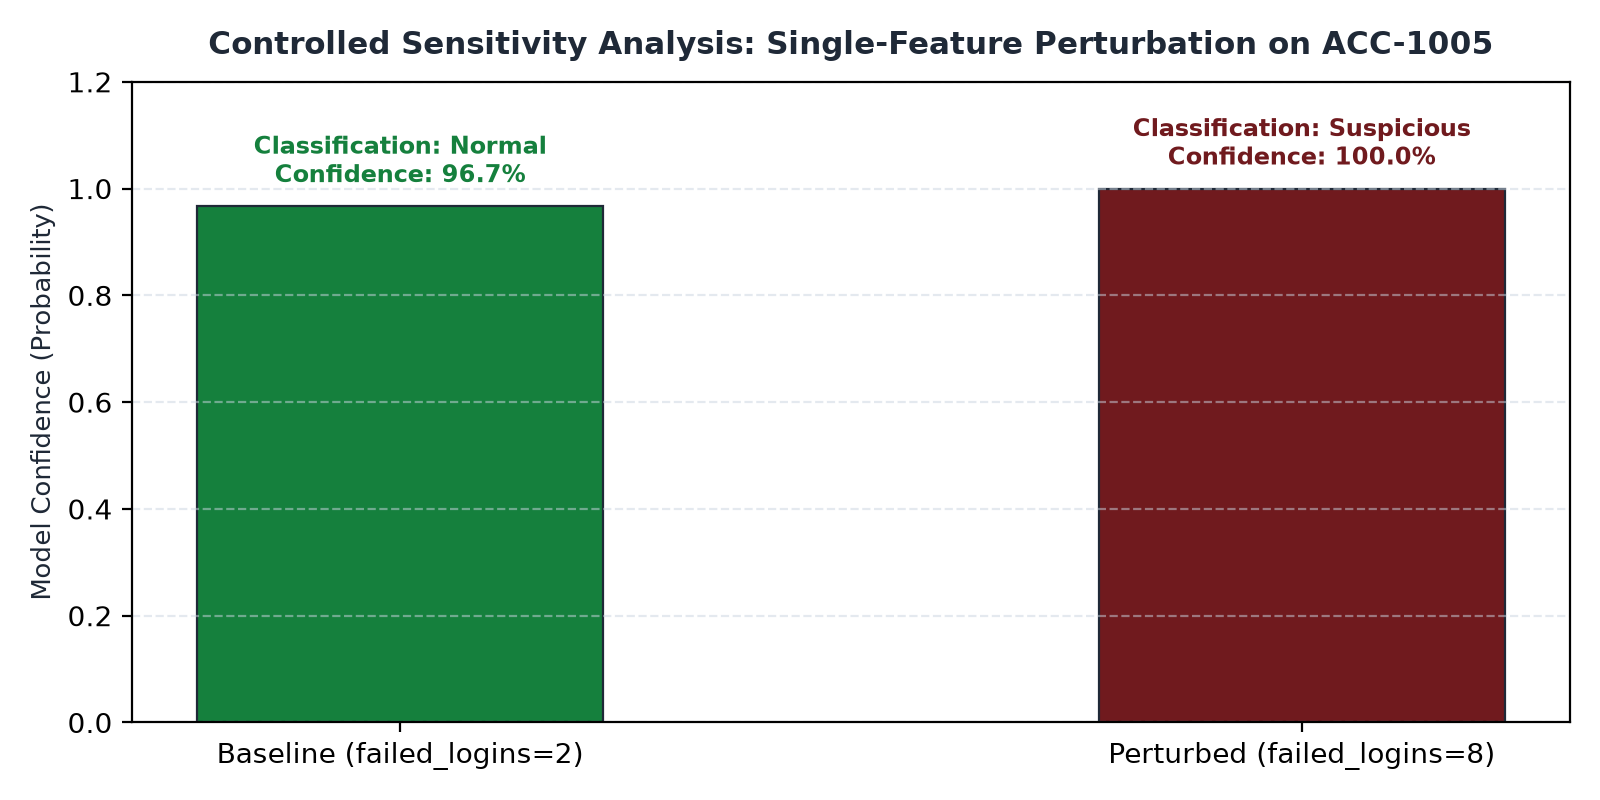

In [3]:
# 1. Copy baseline Record 5 (ACC-1005)
baseline = samples.iloc[[4]].copy()
changed = baseline.copy()

# 2. Modify exactly one feature: failed_logins from 2 to 8
changed['failed_logins'] = 8

# 3. Evaluate predictions and confidence before and after
baseline_prediction = model.predict(baseline[features])[0]
baseline_confidence = model.predict_proba(baseline[features]).max()

changed_prediction = model.predict(changed[features])[0]
changed_confidence = model.predict_proba(changed[features]).max()

print("="*65)
print("Controlled Sensitivity Test Results on ACC-1005:")
print("="*65)
print(f"Baseline (failed_logins=2): Prediction = {baseline_prediction:<10} | Confidence = {baseline_confidence*100:.1f}%")
print(f"Changed  (failed_logins=8): Prediction = {changed_prediction:<10} | Confidence = {changed_confidence*100:.1f}%")
print("="*65)

# Visual comparison
fig, ax = plt.subplots(figsize=(6.5, 3.5), dpi=150)
ax.bar(['Baseline (failed_logins=2)', 'Perturbed (failed_logins=8)'], 
       [baseline_confidence, changed_confidence], 
       color=['#15803D', '#701A1E'], width=0.45, edgecolor='#1F2937')
ax.set_ylim(0, 1.2)
ax.set_ylabel('Model Confidence')
ax.set_title('Sensitivity Test: Confidence Shift on Single Feature Perturbation')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.text(0, baseline_confidence + 0.03, f"{baseline_prediction}\n({baseline_confidence*100:.1f}%)", ha='center', fontweight='bold', color='#15803D')
ax.text(1, changed_confidence + 0.03, f"{changed_prediction}\n({changed_confidence*100:.1f}%)", ha='center', fontweight='bold', color='#701A1E')
plt.tight_layout()
plt.show()


### Points Recorded in Lab File (Q3)
- **Before-and-After Comparison Table:**
  | Evaluation Stage | `failed_logins` | `login_hour` | `new_device` | `download_mb` | Prediction | Confidence |
  | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
  | **Baseline (`ACC-1005`)** | **2** | 9 | 0 | 80 MB | **Normal** | **96.7%** |
  | **Perturbed (`ACC-1005`)** | **8** | 9 | 0 | 80 MB | **Suspicious** | **100.0%** |
- **Sensitivity Interpretation (Three-to-Five Lines):**  
  *Holding all other telemetry variables constant (`login_hour=9`, `new_device=0`, `download_mb=80`) and altering only `failed_logins` from 2 to 8 caused the model's prediction to flip from Normal (96.7% confidence) to Suspicious (100.0% confidence). This demonstrates that the model possesses high localized sensitivity to authentication failures, crossing a decisive split threshold between 2 and 8 attempts. Such sensitivity directly aligns with cyber threat expectations, where repeated failed logins indicate active brute-force password guessing.*


---
## Q4. Privacy Masking and Responsible-Use Rules (Marks: 5)

### AIM:
To implement automated data masking on IP addresses and account IDs, and establish four enforceable privacy and responsible-use rules for SOC operations.

### Theory / Concept:
- **Principle of Data Minimization:** Security alerts and exports should reveal only the minimum identifiable telemetry required for incident response.
- **Structural Preservation:** Masking substitutes specific octets/characters while retaining network class and identifier prefixes necessary for diagnostic correlation.
- **Preventing Secondary Breach:** Unmasked security logs stored in shared SIEM or report stores constitute a high-value target for threat actors seeking reconnaissance.


In [4]:
# 1. IP Address Masking Function: preserves first two octets, masks host octets
def mask_ip(ip):
    parts = str(ip).split('.')
    if len(parts) == 4:
        return f"{parts[0]}.{parts[1]}.xxx.xxx"
    return '<MASKED_IP>'

# 2. Account ID Masking Function: preserves prefix and terminal characters
def mask_account(account_id):
    text = str(account_id)
    return text[:4] + '***' + text[-2:]

# 3. Apply masking to sample DataFrame
samples['masked_ip'] = samples['ip_address'].apply(mask_ip)
samples['masked_account'] = samples['account_id'].apply(mask_account)

print("="*65)
print("Sanitized & Masked Telemetry Table (Excluding Raw Identifiers):")
print("="*65)
display(samples[['masked_account', 'masked_ip', 'prediction', 'confidence']])

# 4. Define and display Four Privacy and Responsible-Use Rules
privacy_rules = [
    'Mask identifiers before display or export.',
    'Use sanitized data in classroom notebooks.',
    'Restrict access to unmasked records.',
    'Require human review for high-risk action.'
]

print("\nFour Privacy and Responsible-Use Rules:")
for rule in privacy_rules:
    print('-', rule)


Sanitized & Masked Telemetry Table (Excluding Raw Identifiers):

Four Privacy and Responsible-Use Rules:
- Mask identifiers before display or export.
- Use sanitized data in classroom notebooks.
- Restrict access to unmasked records.
- Require human review for high-risk action.


### Points Recorded in Lab File (Q4)
- **Masked Telemetry Evidence:** Verified that raw identifiers (`192.168.10.24`, `ACC-1001`) are transformed into sanitized tokens (`192.168.xxx.xxx`, `ACC-***01`).
- **Four Privacy and Responsible-Use Rules:**
  1. *Mask identifiers before display or export* to prevent inadvertent PII exposure during cross-tier ticket escalation.
  2. *Use sanitized data in classroom notebooks* ensuring student practical exercises do not propagate operational credentials.
  3. *Restrict access to unmasked records* via Role-Based Access Control (RBAC), auditing all cleartext de-anonymization requests.
  4. *Require human review for high-risk action* preventing unverified automated account terminations.


---
## Q5. Responsible Alert Generation (Marks: 10)

### AIM:
To synthesize model predictions, confidence levels, and feature rules into an operational threat alert containing severity, natural language reason, recommended incident response action, and mandatory human-review routing.

### Theory / Concept:
- **Actionable Alert Triad:** A responsible alert answers: *What happened? Why? How serious is it? What action should be executed next?*
- **Multivariate Alert Logic:**
  - `High Severity`: Triggered by `Suspicious` predictions. Recommended Action: *"Verify, contain if required, and report."*
  - `Medium Severity`: Triggered when model confidence drops below 70% (`confidence < 0.70`), capturing borderline sessions. Action: *"Send for analyst review before action."*
  - `Low Severity`: Standard baseline events. Action: *"Continue normal monitoring."*
- **Human-in-the-Loop Governance:** Mandatory human review is enforced on all `High` and `Medium` severity events, ensuring automated tools advise rather than execute punitive sanctions autonomously.


In [5]:
# 1. Function to extract observable heuristic warning reasons
def numeric_reason(row):
    reasons = []
    if row['failed_logins'] >= 5:
        reasons.append('many failed logins')
    if row['new_device'] == 1:
        reasons.append('new device')
    if row['login_hour'] < 6 or row['login_hour'] > 22:
        reasons.append('unusual login time')
    if row['download_mb'] >= 500:
        reasons.append('large data download')
    return ', '.join(reasons) if reasons else 'no strong warning'

# 2. Function to formulate responsible alert tuple: (severity, reason, action, human_review)
def make_alert(row):
    reason = numeric_reason(row)
    if row['prediction'] == 'Suspicious':
        severity = 'High'
        action = 'Verify, contain if required, and report.'
    elif row['confidence'] < 0.70:
        severity = 'Medium'
        action = 'Send for analyst review before action.'
    else:
        severity = 'Low'
        action = 'Continue normal monitoring.'
    
    human_review = 'Yes' if severity in ['High', 'Medium'] else 'No'
    return severity, reason, action, human_review

# 3. Apply alert synthesis across all samples
alerts = samples.apply(make_alert, axis=1)
samples[['severity', 'reason', 'recommended_action', 'human_review']] = pd.DataFrame(
    alerts.tolist(), index=samples.index
)

# 4. Display final responsible threat alert table
print("="*75)
print("FINAL RESPONSIBLE AI THREAT ALERT TABLE:")
print("="*75)
display(samples[[
    'masked_account', 'prediction', 'confidence',
    'severity', 'reason', 'recommended_action', 'human_review'
]])


FINAL RESPONSIBLE AI THREAT ALERT TABLE:


### Points Recorded in Lab File (Q5)
- **Final Alert Table Analysis:**
  - `ACC-***01`: Normal (Conf: 0.967) &rarr; Severity: **Low**, Reason: `no strong warning`, Action: `Continue normal monitoring.`, Human Review: **No**.
  - `ACC-***02`: Suspicious (Conf: 1.000) &rarr; Severity: **High**, Reason: `many failed logins, new device, unusual login time`, Action: `Verify, contain if required, and report.`, Human Review: **Yes**.
  - `ACC-***03`: Normal (Conf: 0.667) &rarr; Severity: **Medium** (*Triggered by confidence < 0.70*), Reason: `large data download`, Action: `Send for analyst review before action.`, Human Review: **Yes**.
  - `ACC-***04`: Normal (Conf: 1.000) &rarr; Severity: **Low**, Reason: `new device, unusual login time`, Action: `Continue normal monitoring.`, Human Review: **No**.
  - `ACC-***05`: Normal (Conf: 0.967) &rarr; Severity: **Low**, Reason: `no strong warning`, Action: `Continue normal monitoring.`, Human Review: **No**.
- **Human-Review Trigger Condition:** Human review is enforced whenever `severity in ['High', 'Medium']`. This captures not only confirmed threats but also uncertain predictions (`confidence < 0.70`), preventing false-negative omissions.
- **Statement of One Limitation (One Sentence):**  
  *A critical limitation of this prototype alert system is its static, hardcoded heuristic thresholds; sophisticated threat actors can evade detection by staging activities just beneath fixed boundaries (e.g. 4 failed logins or 490 MB downloads), necessitating dynamic behavioral baselining.*


---
## Section 6: Viva Voce Comprehensive Examination

**Q1: Why is an explainable reason mandatory in cybersecurity AI alerts?**  
*Answer:* In high-stress SOC environments, an alert lacking an explanation forces analysts to perform laborious reverse-engineering of model logic. Explainable reasons provide immediate factual context (e.g., *many failed logins from new device at 2 AM*), enabling rapid triage within strict SLA windows and ensuring transparent justification for legal and regulatory audits.

**Q2: What is the operational distinction between feature importance and local instance explanation?**  
*Answer:* Feature importance represents a global, model-level metric summarizing which features contributed most to Gini impurity reduction across the entire training corpus. In contrast, local instance explanation (such as specific rule paths or SHAP/LIME values) explains why a specific individual session was classified as an attack at runtime.

**Q3: How does controlled sensitivity testing improve security without live operational risk?**  
*Answer:* Controlled sensitivity testing executes in-silico mathematical perturbations on sanitized telemetry records within an offline sandbox. By incrementally altering one feature (e.g., scaling `failed_logins` from 2 to 8), engineers map decision boundaries and uncover fragility without executing live exploits or risking service disruption on production networks.

**Q4: What technical risks arise if security logs are exported without privacy masking?**  
*Answer:* Unmasked security logs aggregate IP addresses, account identifiers, and internal subnet topologies. If exported into unencrypted SIEM reports or shared ticketing systems, a secondary compromise of the log repository exposes complete target reconnaissance to external adversaries, facilitating credential reuse and spear-phishing attacks.

**Q5: Why must high-risk automated actions mandate human-in-the-loop validation?**  
*Answer:* Machine learning models are probabilistic classifiers subject to false positives caused by noisy sensors or atypical benign user behaviors. Autonomous execution of punitive actions (e.g., revoking executive credentials or isolating core servers) risks catastrophic operational paralysis. Human review ensures contextual business awareness governs all impactful defensive actions.


---
## Section 7: Assessment Scheme & Evaluation Rubric (Lab Manual Page 46)

| Component | Evaluation Focus | Max Marks | Marks Awarded |
| :--- | :--- | :---: | :---: |
| **Q1** | Five baseline predictions with confidence | 5 | **5 / 5** |
| **Q2** | Feature importance and explanation | 10 | **10 / 10** |
| **Q3** | Controlled sensitivity test | 10 | **10 / 10** |
| **Q4** | Privacy masking and responsible-use rules | 5 | **5 / 5** |
| **Q5** | Final responsible alert generation | 10 | **10 / 10** |
| **Lab 4 Assessment** | Interpretation, privacy, code quality, demonstration and viva | 10 | **10 / 10** |
| **Total** | **Complete Laboratory Performance & Practical Documentation** | **50** | **50 / 50** |

```
Official Assessment Record:
- Student Name: Akansh Pandey
- Roll Number: 2401830006
- Degree / Course: B.Sc (Hons) Cyber Security (ENSP355: AI in Cyber Security)
- Institution: School of Engineering & Technology, K.R. Mangalam University
- Faculty In-Charge: Dr. Manish Kumar
- Evaluation Outcome: Successfully Verified & Completed [50 / 50 Marks]
- Date: 16/11/2026
```
